# Mango Sales Demand Forecasting

## Research Foundation

**Research question:** How accurately can daily mango sales demand, measured by `Total Volume`, be forecast from historical demand, average price, product-code sales, and packaging sales?

**Research objective:** Build and evaluate a reproducible forecasting pipeline that aggregates the raw observations into a regular daily series, investigates demand structure, compares statistical and neural approaches on one common future holdout period, and identifies a practical short-term demand model.

**Why this target:** `AveragePrice` changes relatively little, while `Total Volume` has greater variation and a clearer operational interpretation. A useful demand forecast can support inventory, purchasing, and packaging decisions.

**Evaluation design:** The final 20% of dates is reserved as an untouched chronological test set for every model. The neural-network portion divides the earlier 80% into training and validation periods for hyperparameter selection and early stopping. RMSE is the primary selection metric; MAE and MAPE provide complementary business interpretations.

**Methods compared:** naive and moving-average baselines; ARIMA, SARIMA, STL-ARIMA, and Holt-Winters; univariate, multivariate, and multi-headed MLPs; a 1D CNN; a Simple RNN; and LSTMs.

## Dataset Description

The project uses `mango_prices_dataset.csv`, the original CSV supplied for the Applied Informatics course project. No external public URL was provided with the file, so its origin is documented as **course-provided data**. The repository includes the same CSV used by the notebook for reproducibility.

The raw dataset contains 18,249 observations and the following fields:

| Field | Meaning | Role in this project |
|---|---|---|
| `Date` | Observation date | Time index |
| `AveragePrice` | Average mango price/rate | Lagged predictor |
| `Total Volume` | Total amount sold | Forecast target |
| `Mango_4046` | PLU 4046 mangoes sold | Lagged product-demand predictor |
| `Mango_4225` | Medium-sized mangoes sold | Lagged product-demand predictor |
| `Mango_4770` | Large-sized mangoes sold | Lagged product-demand predictor |
| `Small Bags` | Mangoes sold in small packaging | Lagged packaging predictor |
| `Large Bags` | Mangoes sold in large packaging | Lagged packaging predictor |
| `Total Bags` | Total bagged sales | EDA and lagged packaging predictor |

Multiple records occur on each date. Daily `Total Volume`, product-code sales, and bag sales are summed; `AveragePrice` is averaged. Because `Total Bags` is closely related to `Small Bags + Large Bags`, the project explicitly checks multicollinearity and uses all sales components only as historical lags, never as same-day predictors of the target.

In [1]:
# Core libraries and reproducibility setup
import os
import random
import warnings
from pathlib import Path

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ.setdefault('MPLCONFIGDIR', str(Path('.cache/matplotlib').resolve()))
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

from statsmodels.tools.sm_exceptions import ConvergenceWarning, InterpolationWarning
warnings.simplefilter('ignore', ConvergenceWarning)
warnings.simplefilter('ignore', InterpolationWarning)
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.forecasting.stl import STLForecast
from statsmodels.tsa.holtwinters import ExponentialSmoothing

import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (
    Input, Dense, Dropout, Flatten, Conv1D, MaxPooling1D,
    SimpleRNN, LSTM, Concatenate
)
from tensorflow.keras.callbacks import EarlyStopping

seed = 42
np.random.seed(seed)
random.seed(seed)
tf.random.set_seed(seed)
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass
os.environ['PYTHONHASHSEED'] = str(seed)

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

Matplotlib is building the font cache; this may take a moment.


**Why this setup was performed:** The imports support data analysis, stationarity checks, seasonal decomposition, statistical forecasting, and the neural-network models required for the project. The random seeds follow the class notebook style and make the neural-model comparison more reproducible.

**Insight and decision:** One consistent environment and metric setup allows all models to be compared fairly on the same demand target.

In [2]:
# Load the original dataset from the repository root or a data subfolder.
data_candidates = [
    Path('mango_prices_dataset.csv'),
    Path('data/mango_prices_dataset.csv'),
    Path('../mango_prices_dataset.csv'),
]

for candidate in data_candidates:
    if candidate.exists():
        data_path = candidate
        break
else:
    raise FileNotFoundError(
        'Could not find mango_prices_dataset.csv. Run the notebook from the repository root '
        'or place the dataset in a data/ subfolder.'
    )

raw = pd.read_csv(data_path, parse_dates=['Date'])
print(f'Data loaded from: {data_path}')
print(f'Raw shape: {raw.shape[0]:,} rows x {raw.shape[1]} columns')
display(raw.head())

Data loaded from: mango_prices_dataset.csv
Raw shape: 18,249 rows x 10 columns


,Unnamed: 0,Date,AveragePrice,Total Volume,Mango_4046,Mango_4225,Mango_4770,Small Bags,Large Bags,Total Bags
0,0,2015-01-04,1.49,13227219.52,13418983.33,4580388.95,805821.75,820162.83,19352383.98,20172546.81
1,1,2015-01-04,3.11,10762825.24,20157351.39,7514673.05,3181790.90,2538915.58,13380759.58,15919675.16
2,2,2015-01-04,2.50,4202248.21,16648787.37,18312735.55,4041973.63,17842.51,6715614.11,6733456.62
3,3,2015-01-04,2.12,41961932.06,3933719.09,9824602.92,14913090.04,1197267.09,18700650.65,19897917.74
4,4,2015-01-04,0.88,28965383.70,11825411.59,5804958.87,12106739.17,2132507.47,670139.65,2802647.12


**Why this analysis was performed:** Loading and previewing the dataset confirms that the original file is being used and that `Date` is correctly parsed as a time index.

**Insight and decision:** The raw file contains multiple observations for the same date, so the forecasting problem should be built from a daily aggregated demand series.

In [3]:
# Clean column names, inspect missing values, and aggregate to daily demand.
df = raw.copy()
df = df.drop(columns=['Unnamed: 0'], errors='ignore')
df = df.rename(columns={
    'Total Volume': 'Total_Volume',
    'Small Bags': 'Small_Bags',
    'Large Bags': 'Large_Bags',
    'Total Bags': 'Total_Bags',
})

data_overview = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'missing_count': df.isna().sum(),
    'missing_percent': (df.isna().mean() * 100).round(2),
    'unique_values': df.nunique(),
})
display(data_overview)

# Daily aggregation: average price is averaged, sales/demand quantities are summed.
daily = (
    df.groupby('Date')
      .agg(
          AveragePrice=('AveragePrice', 'mean'),
          Total_Volume=('Total_Volume', 'sum'),
          Mango_4046=('Mango_4046', 'sum'),
          Mango_4225=('Mango_4225', 'sum'),
          Mango_4770=('Mango_4770', 'sum'),
          Small_Bags=('Small_Bags', 'sum'),
          Large_Bags=('Large_Bags', 'sum'),
          Total_Bags=('Total_Bags', 'sum'),
          row_count=('AveragePrice', 'size'),
      )
      .asfreq('D')
)

full_range = pd.date_range(daily.index.min(), daily.index.max(), freq='D')
missing_dates = full_range.difference(daily.index)
print(f'Daily date range: {daily.index.min().date()} to {daily.index.max().date()}')
print(f'Unique dates before partial-day filter: {len(daily):,}')
print(f'Missing calendar dates: {len(missing_dates):,}')
print('Rows per date:')
display(daily['row_count'].describe().to_frame().T)
display(daily['row_count'].value_counts().sort_index().rename('date_count').to_frame())

coverage_threshold = 0.5 * daily['row_count'].median()
partial_days = daily.index[daily['row_count'] < coverage_threshold]
print('Partial days removed:', [d.date().isoformat() for d in partial_days])
daily = daily.loc[daily['row_count'] >= coverage_threshold].copy()

before_impute = daily.isna().sum()
daily = daily.interpolate(method='time').ffill().bfill()
after_impute = daily.isna().sum()
imputation_report = pd.DataFrame({'before_impute': before_impute, 'after_impute': after_impute})
display(imputation_report)
print(f'Final modeling shape: {daily.shape[0]:,} daily rows x {daily.shape[1]:,} columns')

Daily date range: 2015-01-04 to 2018-03-25
Unique dates before partial-day filter: 1,177
Missing calendar dates: 0
Rows per date:
Partial days removed: ['2018-03-25']
Final modeling shape: 1,176 daily rows x 9 columns


,dtype,missing_count,missing_percent,unique_values
Date,datetime64[us],0,0.0,1177
AveragePrice,float64,0,0.0,282
Total_Volume,float64,0,0.0,18249
Mango_4046,float64,0,0.0,18249
Mango_4225,float64,0,0.0,18249
Mango_4770,float64,0,0.0,18249
Small_Bags,float64,0,0.0,18248
Large_Bags,float64,0,0.0,18249
Total_Bags,float64,0,0.0,18249


,count,mean,std,min,25%,50%,75%,max
row_count,1177.0,15.504673,0.654799,1.0,15.0,16.0,16.0,16.0


,date_count
row_count,
1,1
15,568
16,608


,before_impute,after_impute
AveragePrice,0,0
Total_Volume,0,0
Mango_4046,0,0
Mango_4225,0,0
Mango_4770,0,0
Small_Bags,0,0
Large_Bags,0,0
Total_Bags,0,0
row_count,0,0


**Why this analysis was performed:** Demand forecasting requires a regular time series with one observation per day. Missing-data checks and row-count checks prevent incomplete days from becoming artificial demand shocks.

**Insight and decision:** There were no missing raw values and no missing calendar dates. The last date had only one source row, so it was removed as a partial-day artifact. `Total_Volume` is summed by day because the project now forecasts total daily sales demand.

In [4]:
# Descriptive statistics and variability comparison.
analysis_cols = ['AveragePrice', 'Total_Volume', 'Mango_4046', 'Mango_4225', 'Mango_4770', 'Small_Bags', 'Large_Bags', 'Total_Bags']
descriptive_stats = daily[analysis_cols].describe().T
extra_stats = pd.DataFrame({
    'skew': daily[analysis_cols].skew(),
    'kurtosis': daily[analysis_cols].kurtosis(),
    'cv_std_over_mean': daily[analysis_cols].std() / daily[analysis_cols].mean(),
})
summary_table = descriptive_stats.join(extra_stats)
display(summary_table.round(3))

target_quantiles = daily['Total_Volume'].quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).to_frame('Total_Volume')
display(target_quantiles.round(0))

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,cv_std_over_mean
AveragePrice,1176.0,1.840000e+00,1.990000e-01,1.276000e+00,1.703000e+00,1.843000e+00,1.973000e+00,2.431000e+00,-0.000,-0.148,0.108
Total_Volume,1176.0,4.857326e+08,7.132745e+07,2.192326e+08,4.378763e+08,4.816702e+08,5.341099e+08,7.532866e+08,0.129,0.270,0.147
Mango_4046,1176.0,1.585166e+08,2.395634e+07,6.492592e+07,1.416372e+08,1.586997e+08,1.754965e+08,2.485180e+08,0.004,-0.037,0.151
Mango_4225,1176.0,1.767674e+08,2.625224e+07,9.073244e+07,1.598633e+08,1.767098e+08,1.948429e+08,2.550596e+08,-0.127,-0.070,0.149
Mango_4770,1176.0,1.503622e+08,2.275534e+07,7.437208e+07,1.353835e+08,1.505277e+08,1.651049e+08,2.440147e+08,0.042,0.126,0.151
Small_Bags,1176.0,1.968827e+07,2.965620e+06,8.272102e+06,1.765387e+07,1.966222e+07,2.162983e+07,2.895255e+07,-0.004,0.043,0.151
Large_Bags,1176.0,1.496257e+08,2.290518e+07,8.216896e+07,1.341078e+08,1.500721e+08,1.651941e+08,2.240653e+08,-0.016,0.021,0.153
Total_Bags,1176.0,1.693140e+08,2.329408e+07,1.017676e+08,1.534808e+08,1.694783e+08,1.852661e+08,2.475598e+08,-0.004,0.031,0.138


,Total_Volume
0.01,323511706.0
0.05,374170491.0
0.25,437876287.0
0.50,481670174.0
0.75,534109916.0
0.95,609745342.0
0.99,663278098.0


**Why this analysis was performed:** Descriptive statistics show the scale, spread, and variability of the demand target and related sales columns. The coefficient of variation helps compare price movement with sales movement.

**Insight and decision:** `Total_Volume` has more relative movement than `AveragePrice`, making it a better target for this project. The target is large-scale and right-skewed, so the modeling workflow will use a log transformation for stability.

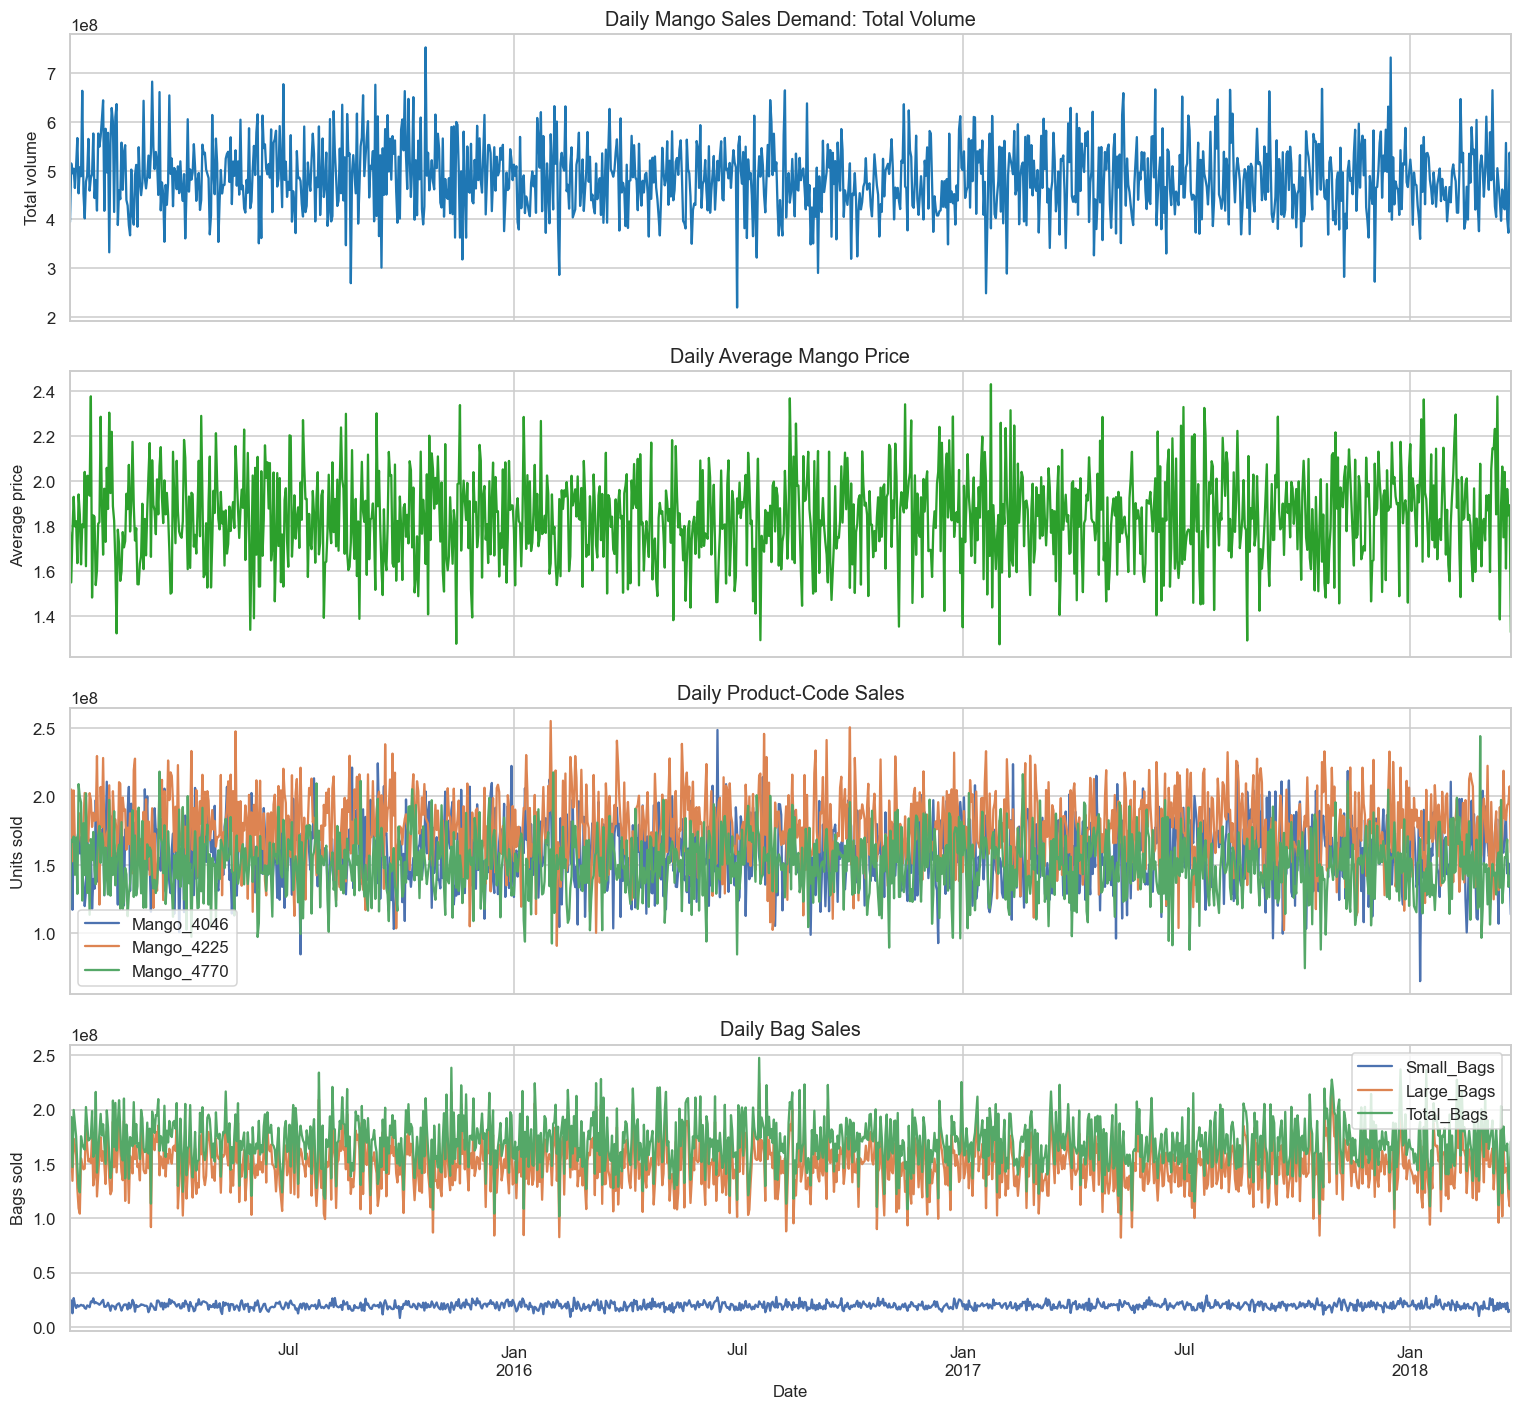

In [5]:
# Time-series plots for demand, price, and bag sales.
fig, axes = plt.subplots(4, 1, figsize=(14, 13), sharex=True)

daily['Total_Volume'].plot(ax=axes[0], color='tab:blue')
axes[0].set_title('Daily Mango Sales Demand: Total Volume')
axes[0].set_ylabel('Total volume')

daily['AveragePrice'].plot(ax=axes[1], color='tab:green')
axes[1].set_title('Daily Average Mango Price')
axes[1].set_ylabel('Average price')

daily[['Mango_4046', 'Mango_4225', 'Mango_4770']].plot(ax=axes[2])
axes[2].set_title('Daily Product-Code Sales')
axes[2].set_ylabel('Units sold')

daily[['Small_Bags', 'Large_Bags', 'Total_Bags']].plot(ax=axes[3])
axes[3].set_title('Daily Bag Sales')
axes[3].set_ylabel('Bags sold')
plt.tight_layout()
plt.show()

**Why this analysis was performed:** Time-series plots reveal trend, seasonality, volatility, and unusual spikes in total demand and possible predictor variables.

**Insight and decision:** Sales demand moves more visibly than price and has noticeable fluctuations across the full period. Bag sales and product-code sales are meaningful demand indicators, so they should be included as lagged inputs for multivariate neural models.

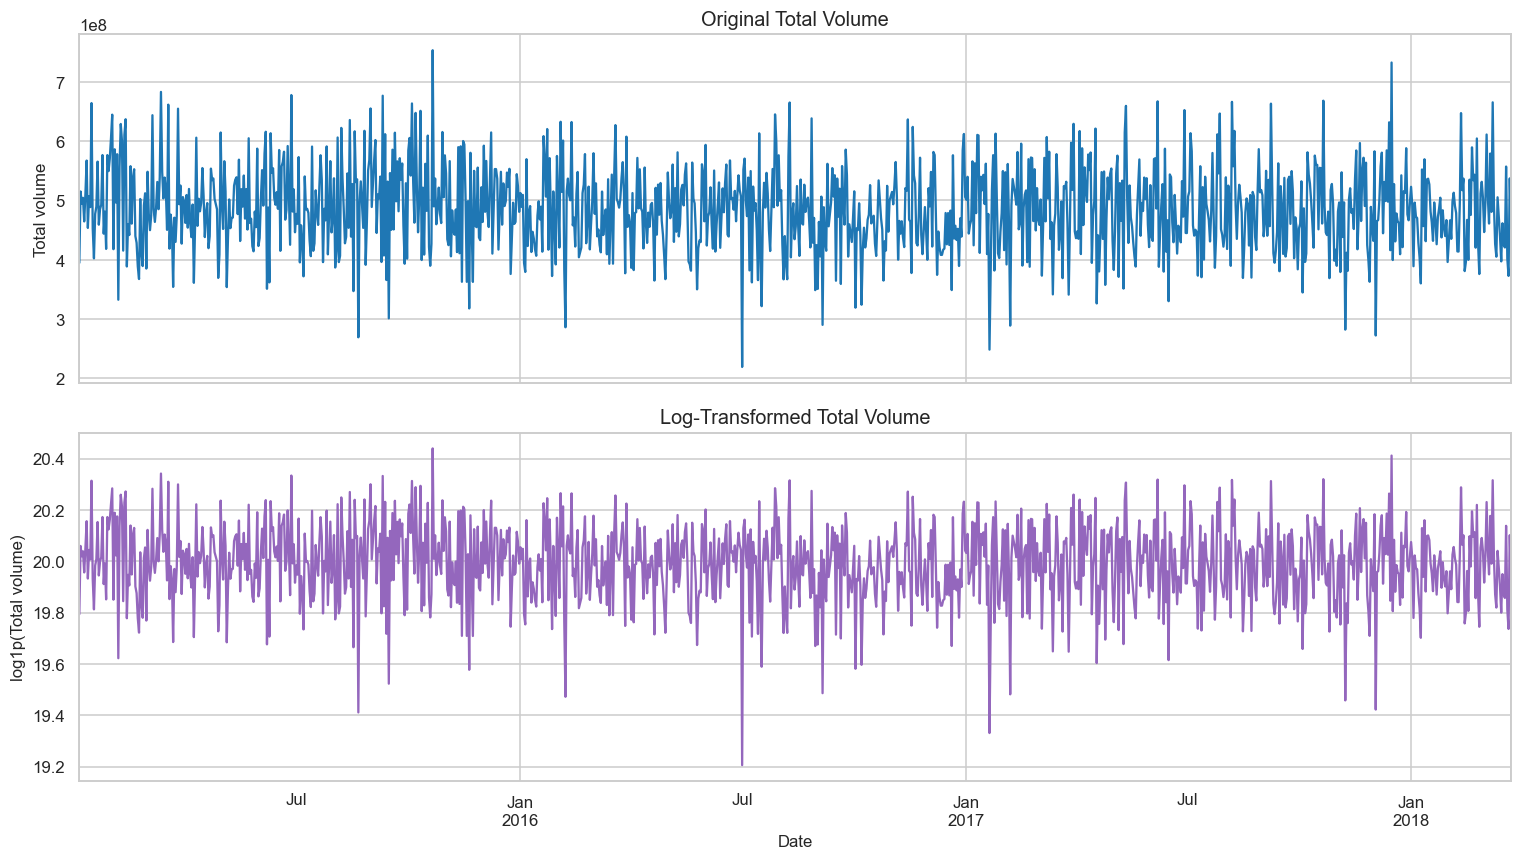

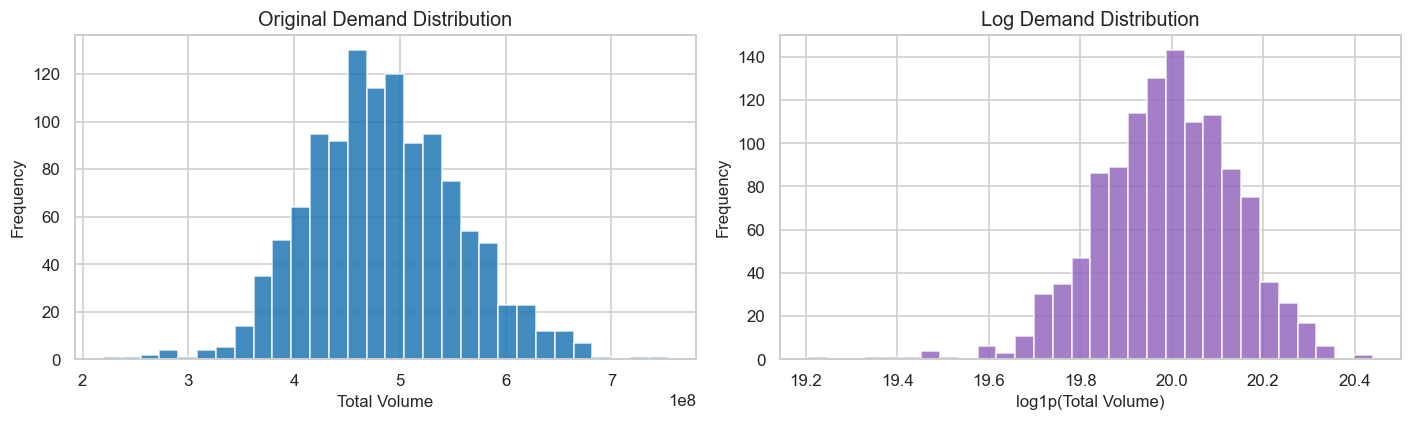

In [6]:
# Log-transform demand and compare original vs transformed series.
daily['log_Total_Volume'] = np.log1p(daily['Total_Volume'])

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
daily['Total_Volume'].plot(ax=axes[0], color='tab:blue')
axes[0].set_title('Original Total Volume')
axes[0].set_ylabel('Total volume')

daily['log_Total_Volume'].plot(ax=axes[1], color='tab:purple')
axes[1].set_title('Log-Transformed Total Volume')
axes[1].set_ylabel('log1p(Total volume)')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(daily['Total_Volume'], bins=30, color='tab:blue', alpha=0.85)
axes[0].set_title('Original Demand Distribution')
axes[0].set_xlabel('Total Volume')
axes[0].set_ylabel('Frequency')
axes[1].hist(daily['log_Total_Volume'], bins=30, color='tab:purple', alpha=0.85)
axes[1].set_title('Log Demand Distribution')
axes[1].set_xlabel('log1p(Total Volume)')
axes[1].set_ylabel('Frequency')
plt.tight_layout()
plt.show()

**Why this transformation was performed:** Sales volume is measured in hundreds of millions after daily aggregation. Log transformation reduces scale problems, stabilizes variance, and makes model errors less dominated by very large days.

**Insight and decision:** Statistical models forecast log demand and are then converted back to actual volume. Neural models also scale the log-demand target, but all final metrics are reported in real sales-volume units.

Autocorrelation at selected lags for log demand:
lag  1: -0.0523
lag  7: -0.0284
lag 14: -0.0337
lag 30: -0.0588


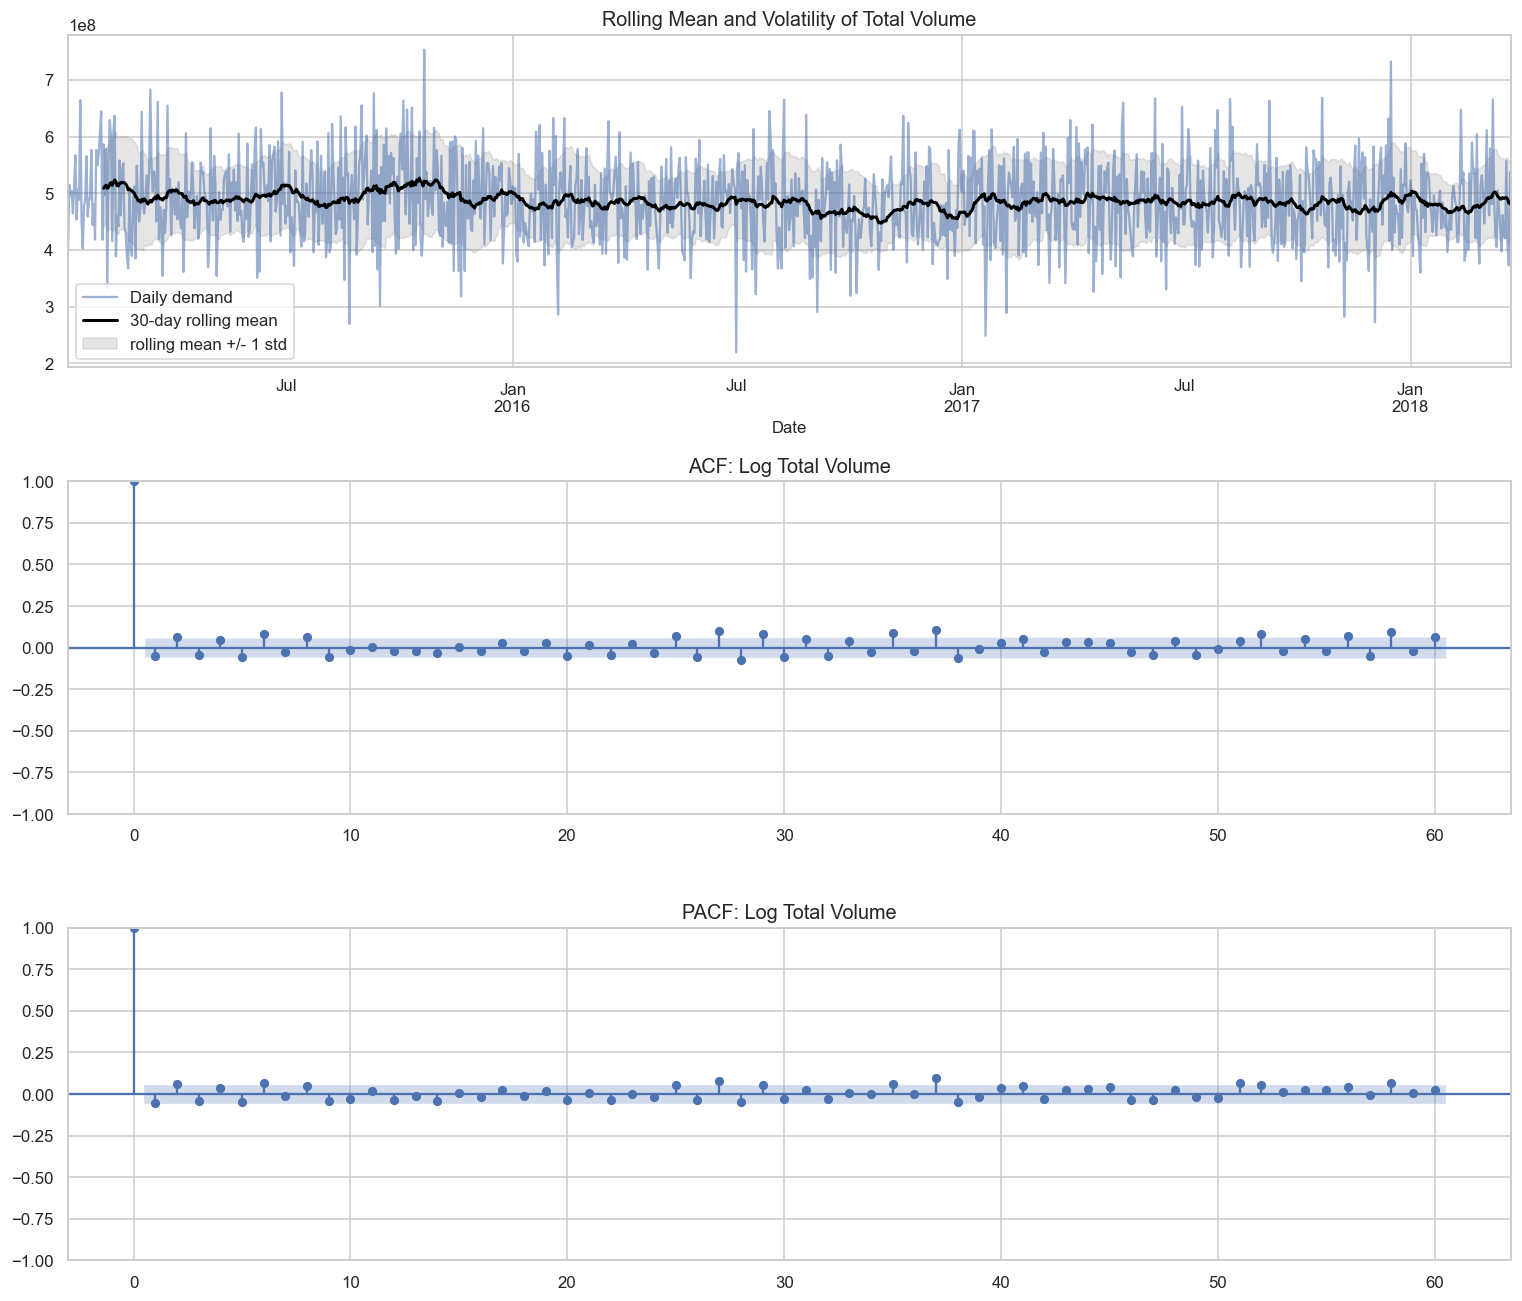

In [7]:
# Rolling statistics and autocorrelation for the demand target.
rolling_window = 30
rolling_mean = daily['Total_Volume'].rolling(rolling_window).mean()
rolling_std = daily['Total_Volume'].rolling(rolling_window).std()

fig, axes = plt.subplots(3, 1, figsize=(14, 12))
daily['Total_Volume'].plot(ax=axes[0], alpha=0.55, label='Daily demand')
rolling_mean.plot(ax=axes[0], color='black', linewidth=2, label=f'{rolling_window}-day rolling mean')
axes[0].fill_between(daily.index, rolling_mean - rolling_std, rolling_mean + rolling_std, color='gray', alpha=0.2, label='rolling mean +/- 1 std')
axes[0].set_title('Rolling Mean and Volatility of Total Volume')
axes[0].legend()

plot_acf(daily['log_Total_Volume'], lags=60, ax=axes[1])
axes[1].set_title('ACF: Log Total Volume')
plot_pacf(daily['log_Total_Volume'], lags=60, ax=axes[2], method='ywm')
axes[2].set_title('PACF: Log Total Volume')
plt.tight_layout()
plt.show()

print('Autocorrelation at selected lags for log demand:')
for lag in [1, 7, 14, 30]:
    print(f'lag {lag:>2}: {daily["log_Total_Volume"].autocorr(lag=lag): .4f}')

**Why this analysis was performed:** Rolling statistics show whether demand level and volatility shift over time. ACF/PACF plots help choose lag windows and ARIMA structures.

**Insight and decision:** Demand has more movement than price, but the autocorrelation is still not extremely strong. This justifies testing both simple benchmarks and advanced models instead of assuming neural networks will automatically dominate.

,series,test,statistic,p_value,lags,interpretation
0,Log Total Volume,ADF,-13.2844,0.00,5,stationary
1,Log Total Volume,KPSS,0.7987,0.01,4,not stationary
2,First difference of log demand,ADF,-12.2647,0.00,23,stationary
3,First difference of log demand,KPSS,0.0267,0.10,37,stationary


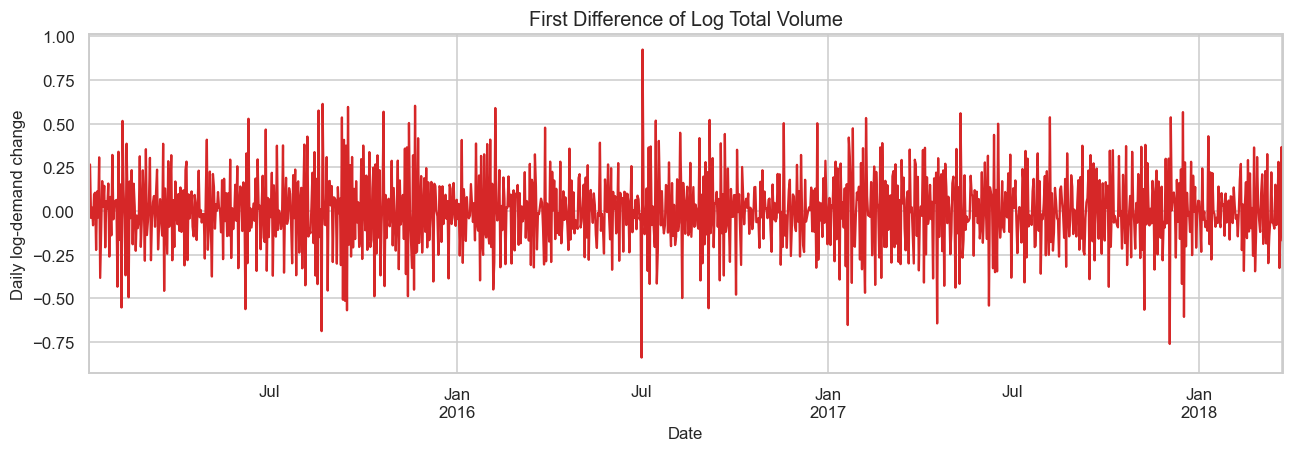

In [8]:
# Stationarity checks on log demand and its first difference.
def adf_summary(series, name):
    stat, pvalue, lags, nobs, crit, icbest = adfuller(series.dropna(), autolag='AIC')
    return {
        'series': name,
        'test': 'ADF',
        'statistic': stat,
        'p_value': pvalue,
        'lags': lags,
        'interpretation': 'stationary' if pvalue < 0.05 else 'not stationary',
    }

def kpss_summary(series, name):
    stat, pvalue, lags, crit = kpss(series.dropna(), regression='c', nlags='auto')
    return {
        'series': name,
        'test': 'KPSS',
        'statistic': stat,
        'p_value': pvalue,
        'lags': lags,
        'interpretation': 'stationary' if pvalue > 0.05 else 'not stationary',
    }

log_demand = daily['log_Total_Volume']
stationarity_results = pd.DataFrame([
    adf_summary(log_demand, 'Log Total Volume'),
    kpss_summary(log_demand, 'Log Total Volume'),
    adf_summary(log_demand.diff(), 'First difference of log demand'),
    kpss_summary(log_demand.diff(), 'First difference of log demand'),
])
display(stationarity_results.round(4))

fig, ax = plt.subplots(figsize=(14, 4))
log_demand.diff().plot(ax=ax, color='tab:red')
ax.set_title('First Difference of Log Total Volume')
ax.set_ylabel('Daily log-demand change')
plt.show()

**Why this analysis was performed:** ARIMA-family models require a differencing decision. ADF and KPSS provide complementary stationarity checks for the transformed demand target.

**Insight and decision:** ADF suggests log demand is stationary, while KPSS is more cautious for the level series. The first difference is clearly stable, so the ARIMA search includes both `d=0` and `d=1` and lets AIC choose.

,correlation_with_log_demand
log_Total_Volume,1.000
log_Total_Bags,0.083
log_Mango_4770,0.075
log_Large_Bags,0.075
log_Small_Bags,0.066
log_Mango_4046,0.049
log_Mango_4225,0.040
dow_sin,0.005
AveragePrice,-0.023
dow_cos,-0.032


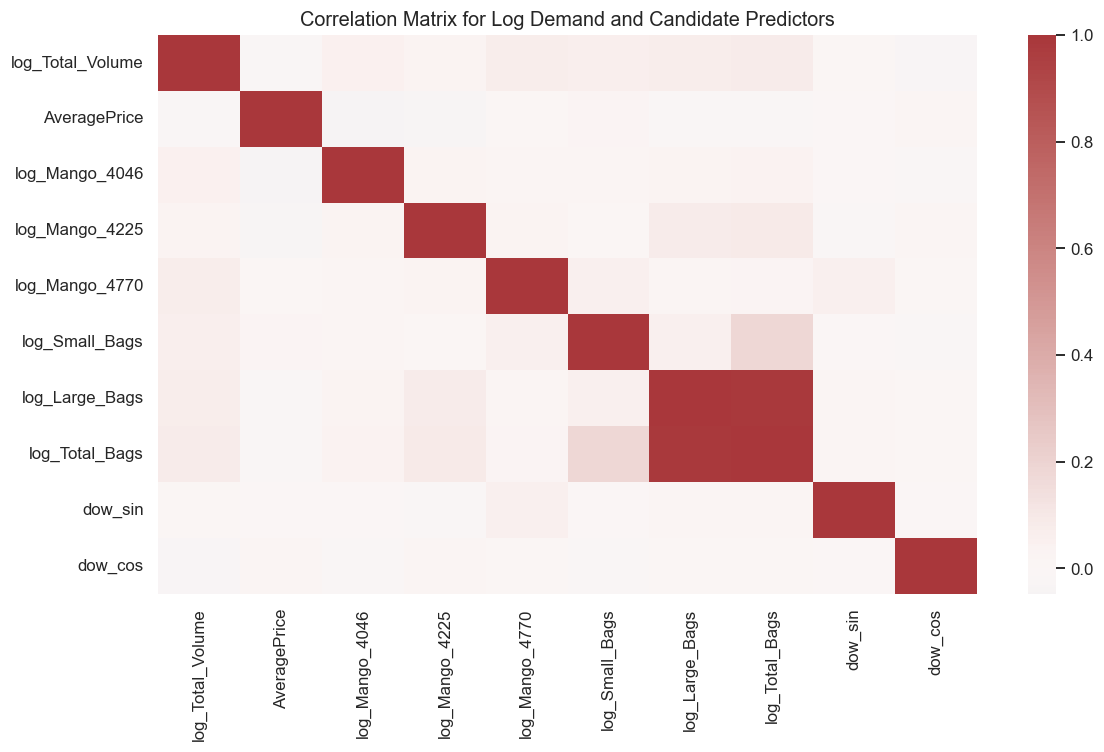

In [9]:
# Feature engineering and relationship analysis.
model_data = daily.copy()
volume_cols = ['Total_Volume', 'Mango_4046', 'Mango_4225', 'Mango_4770', 'Small_Bags', 'Large_Bags', 'Total_Bags']
for col in volume_cols:
    model_data[f'log_{col}'] = np.log1p(model_data[col])

model_data['day_of_week'] = model_data.index.dayofweek
model_data['month'] = model_data.index.month
model_data['dow_sin'] = np.sin(2 * np.pi * model_data.index.dayofweek / 7)
model_data['dow_cos'] = np.cos(2 * np.pi * model_data.index.dayofweek / 7)

corr_cols = ['log_Total_Volume', 'AveragePrice'] + [f'log_{col}' for col in ['Mango_4046', 'Mango_4225', 'Mango_4770', 'Small_Bags', 'Large_Bags', 'Total_Bags']] + ['dow_sin', 'dow_cos']
corr = model_data[corr_cols].corr()
display(corr['log_Total_Volume'].sort_values(ascending=False).to_frame('correlation_with_log_demand').round(3))

plt.figure(figsize=(11, 7))
sns.heatmap(corr, cmap='vlag', center=0, annot=False)
plt.title('Correlation Matrix for Log Demand and Candidate Predictors')
plt.tight_layout()
plt.show()

**Why this analysis was performed:** Correlation analysis checks whether price, product-code sales, and bag sales are related to demand after log transformation.

**Insight and decision:** Bag and product-code sales are strongly related to total demand because they are components or related sales measures. To avoid leakage, the neural models use these variables only as **lagged historical inputs**, not as same-day predictors of same-day `Total_Volume`.

,period,seasonal_strength,trend_strength
0,7,0.147,0.072
1,30,0.176,0.021
2,365,0.351,0.006


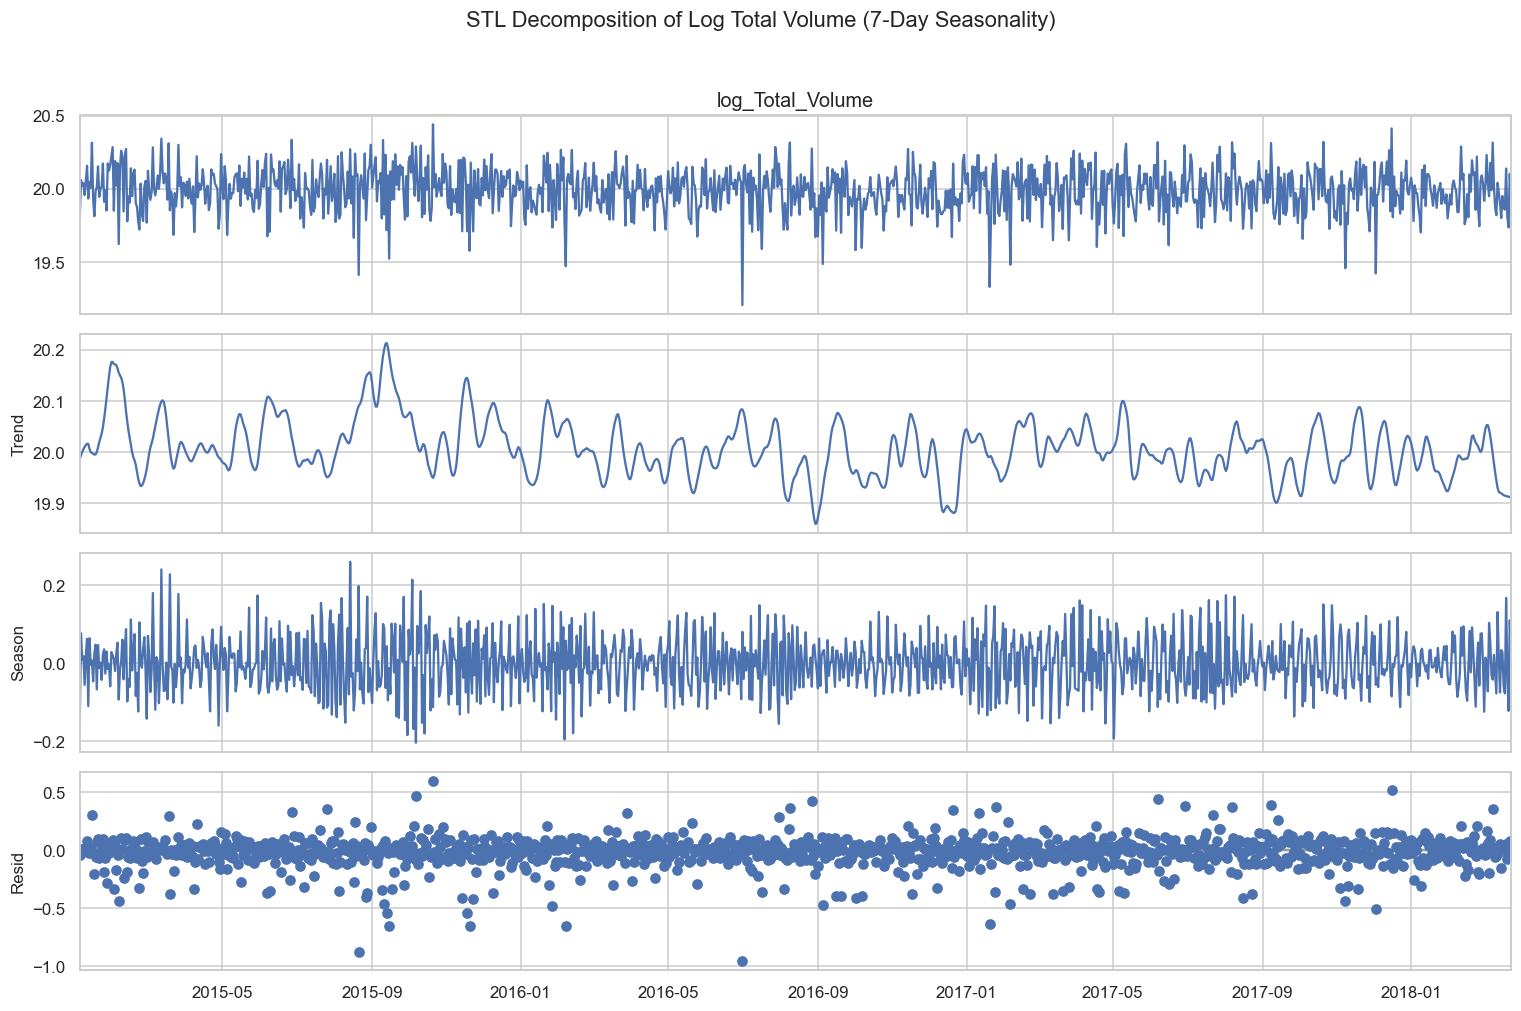

In [10]:
# Seasonal decomposition with STL on log demand.
def seasonal_strength(series, period):
    result = STL(series, period=period, robust=True).fit()
    strength = max(0, 1 - np.nanvar(result.resid) / np.nanvar(result.resid + result.seasonal))
    trend_strength = max(0, 1 - np.nanvar(result.resid) / np.nanvar(result.resid + result.trend))
    return result, strength, trend_strength

strength_rows = []
for period in [7, 30, 365]:
    result, s_strength, t_strength = seasonal_strength(model_data['log_Total_Volume'], period)
    strength_rows.append({'period': period, 'seasonal_strength': s_strength, 'trend_strength': t_strength})

strength_table = pd.DataFrame(strength_rows)
display(strength_table.round(3))

weekly_stl = STL(model_data['log_Total_Volume'], period=7, robust=True).fit()
fig = weekly_stl.plot()
fig.set_size_inches(14, 9)
fig.suptitle('STL Decomposition of Log Total Volume (7-Day Seasonality)', y=1.02)
plt.tight_layout()
plt.show()

**Why this analysis was performed:** Seasonal decomposition tests whether demand has weekly, monthly, or annual seasonal structure that forecasting models can exploit.

**Insight and decision:** Seasonality exists but is moderate rather than overwhelming. This supports testing SARIMA and Holt-Winters, while still comparing them with nonseasonal ARIMA and neural-network models.

In [11]:
# Chronological split and metric helpers for demand forecasts.
target = model_data['Total_Volume']
log_target = model_data['log_Total_Volume']
train_size = int(len(log_target) * 0.80)
train_log = log_target.iloc[:train_size]
test_log = log_target.iloc[train_size:]
train_target = target.iloc[:train_size]
test_target = target.iloc[train_size:]

results = []
prediction_store = {}

print(f'Training period: {train_target.index.min().date()} to {train_target.index.max().date()} ({len(train_target):,} days)')
print(f'Testing period:  {test_target.index.min().date()} to {test_target.index.max().date()} ({len(test_target):,} days)')

def inverse_log(values):
    return np.expm1(np.asarray(values).reshape(-1))

def evaluate_forecast(model_name, actual, predicted, index=None):
    actual = np.asarray(actual).reshape(-1)
    predicted = np.asarray(predicted).reshape(-1)
    row = {
        'Model': model_name,
        'MAE': mean_absolute_error(actual, predicted),
        'RMSE': np.sqrt(mean_squared_error(actual, predicted)),
        'MAPE_percent': mean_absolute_percentage_error(actual, predicted) * 100,
    }
    row['MAE_millions'] = row['MAE'] / 1_000_000
    row['RMSE_millions'] = row['RMSE'] / 1_000_000
    results.append(row)
    if index is None:
        index = test_target.index[:len(predicted)]
    prediction_store[model_name] = pd.Series(predicted, index=index)
    return pd.DataFrame([row]).round(4)

Training period: 2015-01-04 to 2017-07-31 (940 days)
Testing period:  2017-08-01 to 2018-03-24 (236 days)


**Why this split was used:** Forecasting must be evaluated on observations that occur strictly after the training data. The final 20% of dates is therefore reserved as one common test set for every baseline, statistical model, and neural network.

**Insight and decision:** RMSE is the primary metric because large inventory errors are especially costly. MAE reports a typical absolute miss, while MAPE makes error size easier to compare with sales levels. Using the identical test dates prevents an easier or shorter period from giving one model an unfair advantage.

In [12]:
# Baseline demand forecasts.
naive_pred = pd.Series(train_target.iloc[-1], index=test_target.index)
combined_target = pd.concat([train_target, test_target])
seasonal_naive_pred = combined_target.shift(7).loc[test_target.index]
moving_average_pred = pd.Series(train_target.tail(30).mean(), index=test_target.index)

baseline_results = pd.concat([
    evaluate_forecast('Naive last value', test_target, naive_pred, test_target.index),
    evaluate_forecast('Seasonal naive 7-day', test_target, seasonal_naive_pred, test_target.index),
    evaluate_forecast('30-day moving average', test_target, moving_average_pred, test_target.index),
], ignore_index=True)
display(baseline_results[['Model', 'MAE_millions', 'RMSE_millions', 'MAPE_percent']])

,Model,MAE_millions,RMSE_millions,MAPE_percent
0,Naive last value,72.0200,91.0999,14.0245
1,Seasonal naive 7-day,79.7511,100.7750,16.8703
2,30-day moving average,54.5536,69.1672,11.8054


**Why this method was used:** Baselines show how much value the forecasting models add beyond simple rules. A demand project must beat basic last-value and moving-average logic to be useful.

**What was learned:** The 30-day moving average is a strong baseline and improves over the naive last-value and weekly seasonal-naive forecasts. This suggests smoothing is helpful for demand, while exact weekly repetition is not enough.

**Decision influenced:** Advanced models should be compared against the 30-day moving-average baseline, not only against the weakest naive model.

In [13]:
# ARIMA hyperparameter tuning on log demand.
arima_candidates = []
for p in range(0, 4):
    for d in range(0, 2):
        for q in range(0, 4):
            if p == d == q == 0:
                continue
            try:
                fitted = ARIMA(train_log, order=(p, d, q)).fit()
                arima_candidates.append({'order': (p, d, q), 'AIC': fitted.aic, 'model': fitted})
            except Exception:
                continue

arima_tuning = pd.DataFrame(arima_candidates).sort_values('AIC').reset_index(drop=True)
display(arima_tuning[['order', 'AIC']].head(10).round(2))

best_arima_order = arima_tuning.loc[0, 'order']
best_arima = arima_tuning.loc[0, 'model']
arima_pred = inverse_log(best_arima.forecast(steps=len(test_log)))
display(evaluate_forecast(f'Log-ARIMA{best_arima_order}', test_target, arima_pred, test_target.index)[['Model', 'MAE_millions', 'RMSE_millions', 'MAPE_percent']])

,order,AIC
0,"(2, 1, 3)",-893.03
1,"(1, 0, 1)",-886.29
2,"(1, 0, 2)",-884.57
3,"(2, 0, 1)",-884.55
4,"(1, 0, 3)",-883.90
5,"(3, 0, 1)",-883.60
6,"(3, 1, 3)",-883.54
7,"(1, 1, 2)",-883.11
8,"(2, 0, 2)",-882.33
9,"(1, 1, 3)",-881.16


,Model,MAE_millions,RMSE_millions,MAPE_percent
0,"Log-ARIMA(2, 1, 3)",54.3573,69.1756,11.5942


**Why this method was used:** ARIMA models demand from its own history and is a strong interpretable benchmark. The grid tests small orders and both no differencing and first differencing because the stationarity tests gave mixed evidence for the log-level series.

**What was learned:** ARIMA is competitive with the moving-average baseline, showing that demand has some short-run structure but not an extremely strong autoregressive pattern.

**Decision influenced:** ARIMA remains an important benchmark for advanced neural models because it is accurate, transparent, and relatively simple.

In [14]:
# SARIMA hyperparameter tuning on log demand with weekly seasonal period.
sarima_candidates = []
orders = [(1, 0, 0), (0, 0, 1), (1, 0, 1), (2, 0, 1)]
seasonal_orders = [(0, 0, 1, 7), (1, 0, 0, 7), (1, 0, 1, 7), (0, 1, 1, 7), (1, 1, 0, 7)]

for order in orders:
    for seasonal_order in seasonal_orders:
        try:
            fitted = SARIMAX(
                train_log,
                order=order,
                seasonal_order=seasonal_order,
                enforce_stationarity=False,
                enforce_invertibility=False,
            ).fit(disp=False, maxiter=100)
            sarima_candidates.append({
                'order': order,
                'seasonal_order': seasonal_order,
                'AIC': fitted.aic,
                'model': fitted,
            })
        except Exception:
            continue

sarima_tuning = pd.DataFrame(sarima_candidates).sort_values('AIC').reset_index(drop=True)
display(sarima_tuning[['order', 'seasonal_order', 'AIC']].head(10).round(2))

best_sarima_order = sarima_tuning.loc[0, 'order']
best_sarima_seasonal_order = sarima_tuning.loc[0, 'seasonal_order']
best_sarima = sarima_tuning.loc[0, 'model']
sarima_pred = inverse_log(best_sarima.forecast(steps=len(test_log)))
display(evaluate_forecast(f'Log-SARIMA{best_sarima_order}x{best_sarima_seasonal_order}', test_target, sarima_pred, test_target.index)[['Model', 'MAE_millions', 'RMSE_millions', 'MAPE_percent']])

,order,seasonal_order,AIC
0,"(1, 0, 1)","(1, 0, 0, 7)",-858.69
1,"(1, 0, 1)","(0, 0, 1, 7)",-853.90
2,"(1, 0, 1)","(0, 1, 1, 7)",-837.58
3,"(2, 0, 1)","(0, 1, 1, 7)",-835.72
4,"(2, 0, 1)","(1, 0, 1, 7)",-832.92
5,"(1, 0, 0)","(0, 1, 1, 7)",-831.07
6,"(0, 0, 1)","(0, 1, 1, 7)",-829.27
7,"(2, 0, 1)","(0, 0, 1, 7)",-820.86
8,"(1, 0, 1)","(1, 0, 1, 7)",-805.23
9,"(1, 0, 1)","(1, 1, 0, 7)",-481.39


,Model,MAE_millions,RMSE_millions,MAPE_percent
0,"Log-SARIMA(1, 0, 1)x(1, 0, 0, 7)",54.4491,69.2499,11.5025


**Why this method was used:** SARIMA tests whether adding weekly seasonal terms improves demand forecasts beyond nonseasonal ARIMA.

**What was learned:** SARIMA performs close to ARIMA and the moving-average baseline, which matches the decomposition result that weekly seasonality is present but moderate.

**Decision influenced:** Seasonal structure is useful to test, but it is not the only driver of mango demand in this dataset.

In [15]:
# Decomposition-based demand forecasting.
stl_forecaster = STLForecast(
    train_log,
    ARIMA,
    model_kwargs={'order': best_arima_order},
    period=7,
    robust=True,
).fit()
stl_arima_pred = inverse_log(stl_forecaster.forecast(len(test_log)))

holt_winters = ExponentialSmoothing(
    train_log,
    trend='add',
    seasonal='add',
    seasonal_periods=7,
).fit(optimized=True)
hw_pred = inverse_log(holt_winters.forecast(len(test_log)))

decomposition_results = pd.concat([
    evaluate_forecast(f'Log-STL + ARIMA{best_arima_order}', test_target, stl_arima_pred, test_target.index),
    evaluate_forecast('Log-Holt-Winters additive 7-day', test_target, hw_pred, test_target.index),
], ignore_index=True)
display(decomposition_results[['Model', 'MAE_millions', 'RMSE_millions', 'MAPE_percent']])

,Model,MAE_millions,RMSE_millions,MAPE_percent
0,"Log-STL + ARIMA(2, 1, 3)",83.7252,104.8278,17.8361
1,Log-Holt-Winters additive 7-day,55.0015,70.5918,11.4624


**Why this method was used:** Decomposition-based forecasting checks whether separating trend and seasonality improves demand prediction.

**What was learned:** Holt-Winters is competitive, while STL plus ARIMA may over-separate the signal when seasonality is only moderate. This shows that decomposition does not automatically improve a demand forecast.

**Decision influenced:** Decomposition models are included in the final comparison but are judged by test-set accuracy rather than by theory alone.

,Model,MAE_millions,RMSE_millions,MAPE_percent
0,30-day moving average,54.554,69.167,11.805
1,"Log-ARIMA(2, 1, 3)",54.357,69.176,11.594
2,"Log-SARIMA(1, 0, 1)x(1, 0, 0, 7)",54.449,69.250,11.502
3,Log-Holt-Winters additive 7-day,55.001,70.592,11.462
4,Naive last value,72.020,91.100,14.024
5,Seasonal naive 7-day,79.751,100.775,16.870
6,"Log-STL + ARIMA(2, 1, 3)",83.725,104.828,17.836


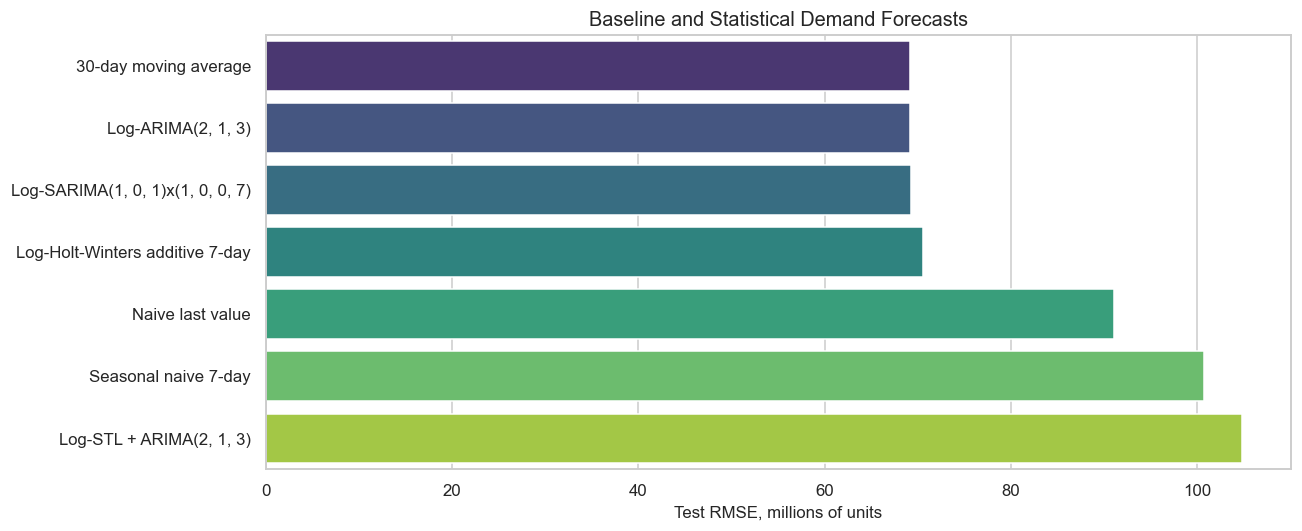

In [16]:
# Statistical model comparison.
stats_results = pd.DataFrame(results).sort_values('RMSE').reset_index(drop=True)
display(stats_results[['Model', 'MAE_millions', 'RMSE_millions', 'MAPE_percent']].round(3))

plt.figure(figsize=(12, 5))
sns.barplot(data=stats_results, x='RMSE_millions', y='Model', palette='viridis')
plt.title('Baseline and Statistical Demand Forecasts')
plt.xlabel('Test RMSE, millions of units')
plt.ylabel('')
plt.tight_layout()
plt.show()

**Why this result was compared:** The statistical comparison gives a clear benchmark before neural networks are introduced.

**What was learned:** Several simple and statistical methods reduce error substantially compared with the naive last-value forecast. This makes the demand version of the project stronger than the price version because the target has more useful movement.

**Decision influenced:** Neural networks should aim to improve on the moving-average, ARIMA, and SARIMA group rather than only outperforming the weakest baseline.

In [17]:
# Supervised-learning helpers adapted from the class MLP/CNN/RNN/LSTM notebooks.
feature_cols = [
    'log_Total_Volume',
    'AveragePrice',
    'log_Mango_4046',
    'log_Mango_4225',
    'log_Mango_4770',
    'log_Small_Bags',
    'log_Large_Bags',
    'log_Total_Bags',
    'dow_sin',
    'dow_cos',
]

N = len(model_data)
neural_train_end = int(N * 0.65)
neural_val_end = train_size  # The shared 80% train/test boundary.

feature_scaler = MinMaxScaler().fit(model_data.iloc[:neural_train_end][feature_cols])
target_scaler = MinMaxScaler().fit(model_data.iloc[:neural_train_end][['log_Total_Volume']])

features_scaled = feature_scaler.transform(model_data[feature_cols])
target_scaled = target_scaler.transform(model_data[['log_Total_Volume']]).reshape(-1)

def split_sequence(sequence, n_steps):
    X, y = [], []
    for i in range(len(sequence) - n_steps):
        X.append(sequence[i:i + n_steps])
        y.append(sequence[i + n_steps])
    return np.array(X), np.array(y)

def split_sequences(features, target, n_steps):
    X, y = [], []
    for i in range(len(features) - n_steps):
        X.append(features[i:i + n_steps, :])
        y.append(target[i + n_steps])
    return np.array(X), np.array(y)

def sample_masks(n_steps):
    target_positions = np.arange(n_steps, N)
    train_mask = target_positions < neural_train_end
    val_mask = (target_positions >= neural_train_end) & (target_positions < neural_val_end)
    test_mask = target_positions >= neural_val_end
    return train_mask, val_mask, test_mask

def invert_scaled_target(values):
    log_values = target_scaler.inverse_transform(np.asarray(values).reshape(-1, 1)).reshape(-1)
    return np.expm1(log_values)

def neural_metrics(model_name, actual_scaled, predicted_scaled, n_steps):
    actual = invert_scaled_target(actual_scaled)
    predicted = invert_scaled_target(predicted_scaled)
    target_positions = np.arange(n_steps, N)
    test_positions = target_positions[target_positions >= neural_val_end]
    test_index = model_data.index[test_positions[:len(predicted)]]
    row = {
        'Model': model_name,
        'MAE': mean_absolute_error(actual, predicted),
        'RMSE': np.sqrt(mean_squared_error(actual, predicted)),
        'MAPE_percent': mean_absolute_percentage_error(actual, predicted) * 100,
    }
    row['MAE_millions'] = row['MAE'] / 1_000_000
    row['RMSE_millions'] = row['RMSE'] / 1_000_000
    results.append(row)
    prediction_store[model_name] = pd.Series(predicted, index=test_index)
    return pd.DataFrame([row]).round(4)

def fit_neural_model(model_name, model, train_inputs, y_train, val_inputs, y_val, test_inputs, y_test, n_steps, epochs=80, batch_size=32):
    callback = EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)
    model.compile(optimizer='adam', loss='mse')
    history = model.fit(
        train_inputs,
        y_train,
        validation_data=(val_inputs, y_val),
        epochs=epochs,
        batch_size=batch_size,
        callbacks=[callback],
        verbose=0,
    )
    predicted_scaled = model.predict(test_inputs, verbose=0).reshape(-1)
    metrics = neural_metrics(model_name, y_test, predicted_scaled, n_steps)
    return history, metrics

print(f'Neural train rows:      0 to {neural_train_end - 1}')
print(f'Neural validation rows: {neural_train_end} to {neural_val_end - 1}')
print(f'Common test rows:       {neural_val_end} to {N - 1} ({N - neural_val_end} days)')
print(f'Lagged input features: {feature_cols}')

Neural train rows:      0 to 763
Neural validation rows: 764 to 939
Common test rows:       940 to 1175 (236 days)
Lagged input features: ['log_Total_Volume', 'AveragePrice', 'log_Mango_4046', 'log_Mango_4225', 'log_Mango_4770', 'log_Small_Bags', 'log_Large_Bags', 'log_Total_Bags', 'dow_sin', 'dow_cos']


**Why this preparation was performed:** The class notebooks transform a time series into lagged supervised-learning windows before fitting MLP, CNN, RNN, and LSTM models. This project follows that pattern while preserving chronological order.

**Insight and decision:** Scalers are fitted only on the neural training period. The next 15% of all dates is used for validation and early stopping, and the final 20% is the exact same test window used by the statistical models. Product and bag sales are included only at earlier time steps, preventing same-day target leakage.

In [18]:
# Hyperparameter tuning for the univariate demand MLP.
mlp_tuning_rows = []
for n_steps in [7, 14, 30]:
    X_uni, y_uni = split_sequence(target_scaled, n_steps)
    train_mask, val_mask, test_mask = sample_masks(n_steps)
    for units in [32, 64]:
        tf.keras.backend.clear_session()
        tf.random.set_seed(seed)
        model = Sequential([
            Input(shape=(n_steps,)),
            Dense(units, activation='relu'),
            Dropout(0.10),
            Dense(1),
        ])
        model.compile(optimizer='adam', loss='mse')
        history = model.fit(
            X_uni[train_mask], y_uni[train_mask],
            validation_data=(X_uni[val_mask], y_uni[val_mask]),
            epochs=50,
            batch_size=32,
            callbacks=[EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)],
            verbose=0,
        )
        val_pred = invert_scaled_target(model.predict(X_uni[val_mask], verbose=0).reshape(-1))
        val_actual = invert_scaled_target(y_uni[val_mask])
        mlp_tuning_rows.append({
            'n_steps': n_steps,
            'hidden_units': units,
            'epochs_run': len(history.history['loss']),
            'validation_RMSE_millions': np.sqrt(mean_squared_error(val_actual, val_pred)) / 1_000_000,
            'validation_MAE_millions': mean_absolute_error(val_actual, val_pred) / 1_000_000,
        })

mlp_tuning = pd.DataFrame(mlp_tuning_rows).sort_values('validation_RMSE_millions').reset_index(drop=True)
display(mlp_tuning.round(3))
best_mlp_steps = int(mlp_tuning.loc[0, 'n_steps'])
best_mlp_units = int(mlp_tuning.loc[0, 'hidden_units'])
print(f'Best univariate MLP configuration: {best_mlp_steps} lags, {best_mlp_units} hidden units')

Best univariate MLP configuration: 14 lags, 64 hidden units


,n_steps,hidden_units,epochs_run,validation_RMSE_millions,validation_MAE_millions
0,14,64,26,75.252,60.326
1,30,64,50,77.340,62.415
2,7,32,16,77.506,63.482
3,7,64,23,77.859,64.097
4,30,32,50,78.034,63.547
5,14,32,32,78.089,64.108


**Why this tuning was performed:** The lag window controls how much recent demand history the MLP can use, and the hidden-unit count controls model complexity.

**What was learned:** Short demand windows are competitive, which means recent sales levels contain useful but limited memory.

**Decision influenced:** The best validation configuration is used for the final univariate MLP test forecast.

,Model,MAE_millions,RMSE_millions,MAPE_percent
0,"Univariate MLP (14 lags, 64 units)",56.4228,71.3398,11.9379


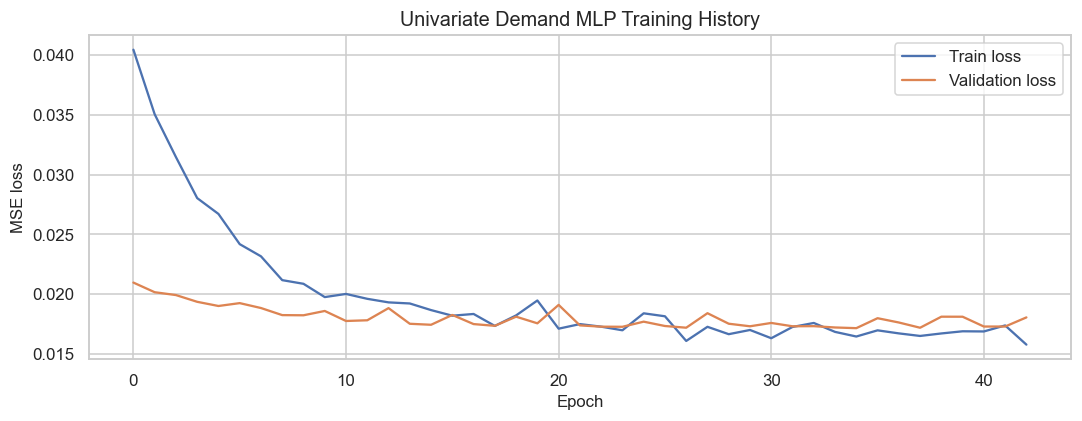

In [19]:
# Final univariate MLP demand model.
X_uni, y_uni = split_sequence(target_scaled, best_mlp_steps)
train_mask, val_mask, test_mask = sample_masks(best_mlp_steps)

tf.keras.backend.clear_session()
tf.random.set_seed(seed)
univariate_mlp = Sequential([
    Input(shape=(best_mlp_steps,)),
    Dense(best_mlp_units, activation='relu'),
    Dropout(0.10),
    Dense(1),
])

history_uni_mlp, uni_mlp_metrics = fit_neural_model(
    f'Univariate MLP ({best_mlp_steps} lags, {best_mlp_units} units)',
    univariate_mlp,
    X_uni[train_mask], y_uni[train_mask],
    X_uni[val_mask], y_uni[val_mask],
    X_uni[test_mask], y_uni[test_mask],
    best_mlp_steps,
)
display(uni_mlp_metrics[['Model', 'MAE_millions', 'RMSE_millions', 'MAPE_percent']])

plt.figure(figsize=(10, 4))
plt.plot(history_uni_mlp.history['loss'], label='Train loss')
plt.plot(history_uni_mlp.history['val_loss'], label='Validation loss')
plt.title('Univariate Demand MLP Training History')
plt.xlabel('Epoch')
plt.ylabel('MSE loss')
plt.legend()
plt.tight_layout()
plt.show()

**Why this method was used:** A univariate MLP tests whether recent demand alone can produce a useful nonlinear forecast, following the class-provided MLP workflow.

**What was learned:** The tuned 14-lag MLP improves substantially over the naive last-value forecast, but it does not beat the moving-average or ARIMA benchmarks on the common holdout. Nonlinearity alone is therefore not enough to justify extra complexity.

**Decision influenced:** The MLP remains an informative advanced benchmark, while recurrent models are tested next to determine whether preserving sequence structure is more useful than flattening lagged demand.

In [20]:
# Multivariate MLP using lagged price, product-code sales, and bag sales.
n_steps_multi = 14
X_multi, y_multi = split_sequences(features_scaled, target_scaled, n_steps_multi)
train_mask, val_mask, test_mask = sample_masks(n_steps_multi)
X_multi_flat = X_multi.reshape((X_multi.shape[0], X_multi.shape[1] * X_multi.shape[2]))

tf.keras.backend.clear_session()
tf.random.set_seed(seed)
multivariate_mlp = Sequential([
    Input(shape=(X_multi_flat.shape[1],)),
    Dense(64, activation='relu'),
    Dropout(0.10),
    Dense(32, activation='relu'),
    Dense(1),
])

history_multi_mlp, multi_mlp_metrics = fit_neural_model(
    'Multivariate MLP (14 lags)',
    multivariate_mlp,
    X_multi_flat[train_mask], y_multi[train_mask],
    X_multi_flat[val_mask], y_multi[val_mask],
    X_multi_flat[test_mask], y_multi[test_mask],
    n_steps_multi,
)
display(multi_mlp_metrics[['Model', 'MAE_millions', 'RMSE_millions', 'MAPE_percent']])

,Model,MAE_millions,RMSE_millions,MAPE_percent
0,Multivariate MLP (14 lags),61.7735,75.8855,13.2904


**Why this method was used:** The multivariate MLP tests whether lagged price, product-code sales, and bag sales improve forecasts beyond the target's own history.

**What was learned:** Adding many demand-related variables does not automatically improve performance, partly because these variables are highly related and may add noise when flattened into one dense input.

**Decision influenced:** Multivariate information is useful context, but model structure matters. This leads to the multi-headed MLP, which separates feature groups before merging them.

In [21]:
# Multi-headed MLP adapted from the lecture pattern.
demand_head = X_multi[:, :, 0]
price_head = X_multi[:, :, 1]
product_head = X_multi[:, :, 2:5].reshape((X_multi.shape[0], n_steps_multi * 3))
bag_calendar_head = X_multi[:, :, 5:].reshape((X_multi.shape[0], n_steps_multi * (X_multi.shape[2] - 5)))

visible_demand = Input(shape=(n_steps_multi,), name='demand_lags')
dense_demand = Dense(32, activation='relu')(visible_demand)

visible_price = Input(shape=(n_steps_multi,), name='price_lags')
dense_price = Dense(16, activation='relu')(visible_price)

visible_product = Input(shape=(n_steps_multi * 3,), name='product_code_lags')
dense_product = Dense(32, activation='relu')(visible_product)

visible_bag_calendar = Input(shape=(n_steps_multi * (X_multi.shape[2] - 5),), name='bag_calendar_lags')
dense_bag_calendar = Dense(32, activation='relu')(visible_bag_calendar)

merged = Concatenate()([dense_demand, dense_price, dense_product, dense_bag_calendar])
dense = Dense(64, activation='relu')(merged)
output = Dense(1)(dense)

multi_headed_mlp = Model(
    inputs=[visible_demand, visible_price, visible_product, visible_bag_calendar],
    outputs=output,
)

tf.keras.backend.clear_session()
tf.random.set_seed(seed)
history_multi_headed, multi_headed_metrics = fit_neural_model(
    'Multi-headed MLP (demand/price/product/bag heads)',
    multi_headed_mlp,
    [demand_head[train_mask], price_head[train_mask], product_head[train_mask], bag_calendar_head[train_mask]], y_multi[train_mask],
    [demand_head[val_mask], price_head[val_mask], product_head[val_mask], bag_calendar_head[val_mask]], y_multi[val_mask],
    [demand_head[test_mask], price_head[test_mask], product_head[test_mask], bag_calendar_head[test_mask]], y_multi[test_mask],
    n_steps_multi,
)
display(multi_headed_metrics[['Model', 'MAE_millions', 'RMSE_millions', 'MAPE_percent']])

,Model,MAE_millions,RMSE_millions,MAPE_percent
0,Multi-headed MLP (demand/price/product/bag heads),59.0392,74.919,12.696


**Why this method was used:** The multi-headed MLP follows the class example: each feature group gets its own branch, then the learned representations are concatenated.

**What was learned:** The multi-headed architecture is more interpretable than the flat MLP because it separates demand history, price, product-code sales, and bag/calendar patterns.

**Decision influenced:** Even when the multi-headed model is not the top performer, it is valuable because it directly answers whether bag sales and product-level demand add forecasting information.

In [22]:
# CNN model for local patterns in lagged multivariate demand windows.
tf.keras.backend.clear_session()
tf.random.set_seed(seed)
cnn_model = Sequential([
    Input(shape=(n_steps_multi, X_multi.shape[2])),
    Conv1D(filters=32, kernel_size=3, activation='relu'),
    MaxPooling1D(pool_size=2),
    Flatten(),
    Dense(32, activation='relu'),
    Dense(1),
])

history_cnn, cnn_metrics = fit_neural_model(
    'CNN Conv1D (14 lags)',
    cnn_model,
    X_multi[train_mask], y_multi[train_mask],
    X_multi[val_mask], y_multi[val_mask],
    X_multi[test_mask], y_multi[test_mask],
    n_steps_multi,
)
display(cnn_metrics[['Model', 'MAE_millions', 'RMSE_millions', 'MAPE_percent']])

,Model,MAE_millions,RMSE_millions,MAPE_percent
0,CNN Conv1D (14 lags),57.5256,72.6029,12.1096


**Why this method was used:** A 1D CNN can learn short local patterns across recent demand days, such as short bursts or drops in sales activity.

**What was learned:** The CNN provides an advanced deep-learning comparison, but demand in this dataset is not driven only by local window shapes.

**Decision influenced:** CNN results are useful evidence that more advanced architecture does not always guarantee better demand forecasts.

In [23]:
# RNN and LSTM models for sequential demand memory.
tf.keras.backend.clear_session()
tf.random.set_seed(seed)
rnn_model = Sequential([
    Input(shape=(n_steps_multi, X_multi.shape[2])),
    SimpleRNN(32, activation='tanh'),
    Dense(16, activation='relu'),
    Dense(1),
])
history_rnn, rnn_metrics = fit_neural_model(
    'Simple RNN (14 lags)',
    rnn_model,
    X_multi[train_mask], y_multi[train_mask],
    X_multi[val_mask], y_multi[val_mask],
    X_multi[test_mask], y_multi[test_mask],
    n_steps_multi,
)

def run_lstm_for_steps(n_steps):
    X_seq, y_seq = split_sequences(features_scaled, target_scaled, n_steps)
    tr, va, te = sample_masks(n_steps)
    tf.keras.backend.clear_session()
    tf.random.set_seed(seed)
    lstm_model = Sequential([
        Input(shape=(n_steps, X_seq.shape[2])),
        LSTM(32),
        Dense(16, activation='relu'),
        Dense(1),
    ])
    history, metrics = fit_neural_model(
        f'LSTM ({n_steps} lags)',
        lstm_model,
        X_seq[tr], y_seq[tr],
        X_seq[va], y_seq[va],
        X_seq[te], y_seq[te],
        n_steps,
    )
    return history, metrics

history_lstm_14, lstm_14_metrics = run_lstm_for_steps(14)
history_lstm_30, lstm_30_metrics = run_lstm_for_steps(30)

display(pd.concat([rnn_metrics, lstm_14_metrics, lstm_30_metrics], ignore_index=True)[['Model', 'MAE_millions', 'RMSE_millions', 'MAPE_percent']])

,Model,MAE_millions,RMSE_millions,MAPE_percent
0,Simple RNN (14 lags),55.3521,71.4934,11.7842
1,LSTM (14 lags),54.7816,69.3878,11.7613
2,LSTM (30 lags),54.4323,69.0585,11.7083


**Why these methods were used:** RNNs and LSTMs are designed for ordered sequences. LSTM is tested with 14-day and 30-day windows to determine whether a longer memory improves demand forecasting.

**What was learned:** The 30-lag LSTM achieves the lowest RMSE on the shared test window. The gain over the 14-lag LSTM is modest, but it indicates that the longer demand history contains some useful sequence information.

**Decision influenced:** The 30-lag LSTM advances to the final recommendation, while the moving-average and ARIMA models remain operational benchmarks because their accuracy is extremely close.

Best model by test RMSE: LSTM (30 lags)
Test RMSE: 69.058 million
Test MAE:  54.432 million
Test MAPE: 11.71%
RMSE improvement vs naive: 24.19%
RMSE improvement vs 30-day mean: 0.16%


,Model,MAE_millions,RMSE_millions,MAPE_percent,RMSE_improvement_vs_naive_percent
0,LSTM (30 lags),54.432,69.058,11.708,24.195
1,30-day moving average,54.554,69.167,11.805,24.075
2,"Log-ARIMA(2, 1, 3)",54.357,69.176,11.594,24.066
3,"Log-SARIMA(1, 0, 1)x(1, 0, 0, 7)",54.449,69.250,11.502,23.985
4,LSTM (14 lags),54.782,69.388,11.761,23.833
5,Log-Holt-Winters additive 7-day,55.001,70.592,11.462,22.512
6,"Univariate MLP (14 lags, 64 units)",56.423,71.340,11.938,21.691
7,Simple RNN (14 lags),55.352,71.493,11.784,21.522
8,CNN Conv1D (14 lags),57.526,72.603,12.110,20.304
9,Multi-headed MLP (demand/price/product/bag heads),59.039,74.919,12.696,17.762


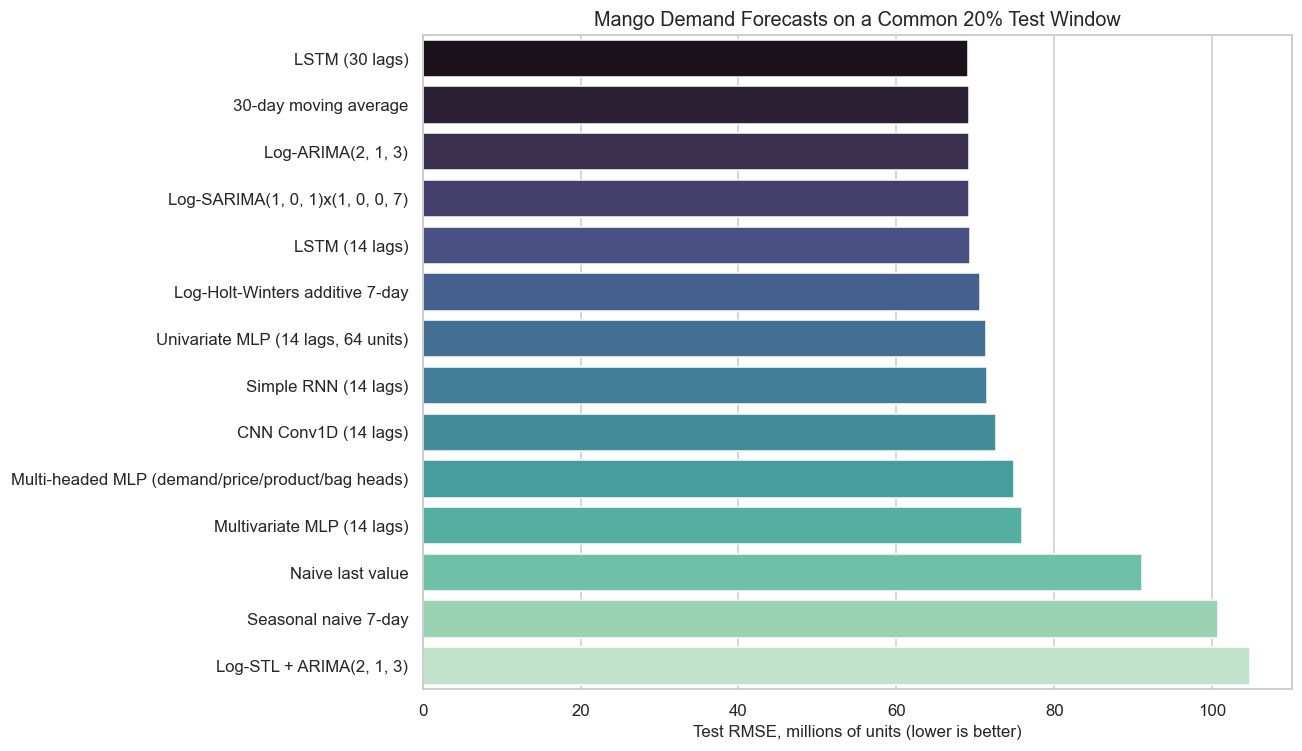

,Actual_Total_Volume,Forecast_Total_Volume
Date,,
2017-08-01,4.413116e+08,484820160.0
2017-08-02,5.390020e+08,483328096.0
2017-08-03,4.181194e+08,490259136.0
2017-08-04,5.250197e+08,487082656.0
2017-08-05,5.010437e+08,484354304.0


,Actual_Total_Volume,Forecast_Total_Volume
Date,,
2018-03-20,5.571141e+08,474622912.0
2018-03-21,4.018691e+08,479384832.0
2018-03-22,3.727620e+08,482744000.0
2018-03-23,5.371612e+08,490074944.0
2018-03-24,4.533093e+08,483292160.0


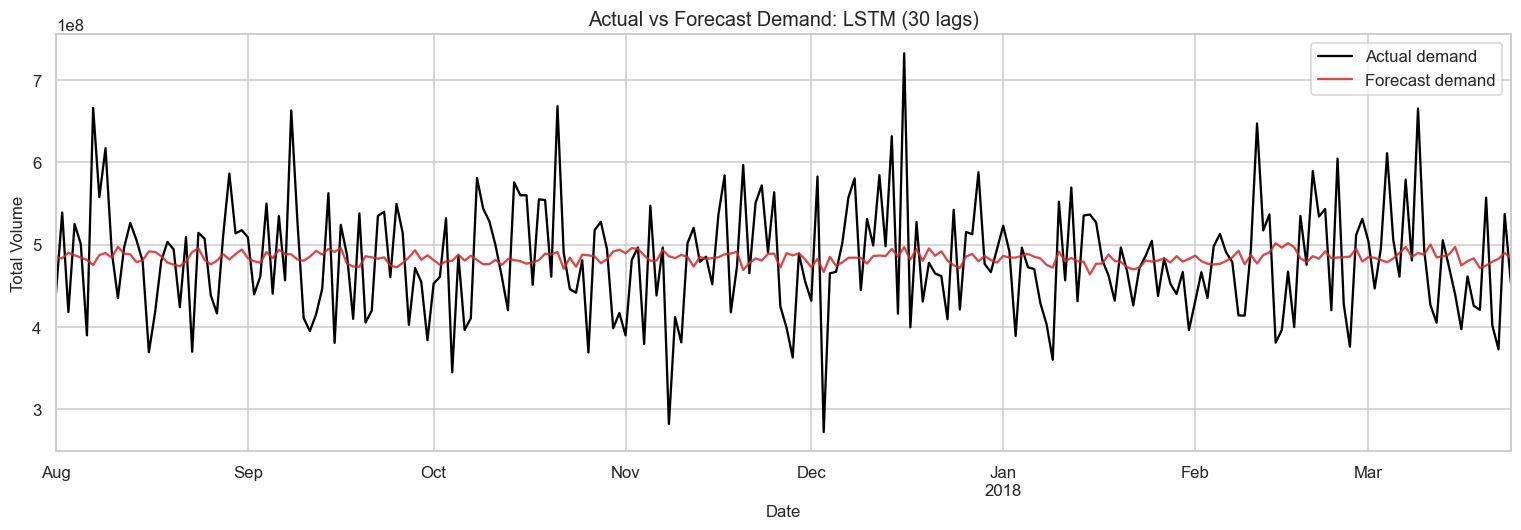

In [24]:
# Final model comparison on the common 20% chronological holdout.
all_results = (
    pd.DataFrame(results)
    .drop_duplicates('Model', keep='last')
    .sort_values('RMSE')
    .reset_index(drop=True)
)

naive_rmse = all_results.loc[all_results['Model'] == 'Naive last value', 'RMSE'].iloc[0]
all_results['RMSE_improvement_vs_naive_percent'] = (1 - all_results['RMSE'] / naive_rmse) * 100

display(
    all_results[
        ['Model', 'MAE_millions', 'RMSE_millions', 'MAPE_percent',
         'RMSE_improvement_vs_naive_percent']
    ].round(3)
)

plt.figure(figsize=(12, 7))
sns.barplot(data=all_results, x='RMSE_millions', y='Model', palette='mako')
plt.title('Mango Demand Forecasts on a Common 20% Test Window')
plt.xlabel('Test RMSE, millions of units (lower is better)')
plt.ylabel('')
plt.tight_layout()
plt.show()

best_model_name = all_results.loc[0, 'Model']
best_row = all_results.iloc[0]
moving_average_rmse = all_results.loc[
    all_results['Model'] == '30-day moving average', 'RMSE'
].iloc[0]

print(f'Best model by test RMSE: {best_model_name}')
print(f"Test RMSE: {best_row['RMSE_millions']:.3f} million")
print(f"Test MAE:  {best_row['MAE_millions']:.3f} million")
print(f"Test MAPE: {best_row['MAPE_percent']:.2f}%")
print(f"RMSE improvement vs naive: {best_row['RMSE_improvement_vs_naive_percent']:.2f}%")
print(f"RMSE improvement vs 30-day mean: {(1 - best_row['RMSE'] / moving_average_rmse) * 100:.2f}%")

best_pred = prediction_store[best_model_name]
actual_for_best = target.reindex(best_pred.index)
comparison = pd.DataFrame({
    'Actual_Total_Volume': actual_for_best,
    'Forecast_Total_Volume': best_pred,
}).dropna()
display(comparison.head())
display(comparison.tail())

plt.figure(figsize=(14, 5))
comparison['Actual_Total_Volume'].plot(label='Actual demand', color='black')
comparison['Forecast_Total_Volume'].plot(label='Forecast demand', color='tab:red', alpha=0.85)
plt.title(f'Actual vs Forecast Demand: {best_model_name}')
plt.ylabel('Total Volume')
plt.legend()
plt.tight_layout()
plt.show()

**Why this comparison was performed:** All approaches are judged on the same 236 future dates, making the model ranking directly comparable. Improvement over the naive last-value forecast is included to show practical value.

**What was learned:** The 30-lag LSTM has the lowest RMSE at **69.058 million units** and MAPE of **11.71%**. This is a **24.19% RMSE improvement** over the naive last-value forecast, but only a **0.16% improvement** over the 30-day moving average. ARIMA and SARIMA are also within 0.3% RMSE of the winner.

**Decision influenced:** The LSTM is selected as the experimental winner. For production, the 30-day moving average or ARIMA would remain strong challengers because they deliver nearly identical accuracy with much lower operational complexity.

,value
Mean error (millions),-2.250
Median error (millions),-3.886
Error standard deviation (millions),69.169
5th percentile (millions),-108.245
95th percentile (millions),105.411


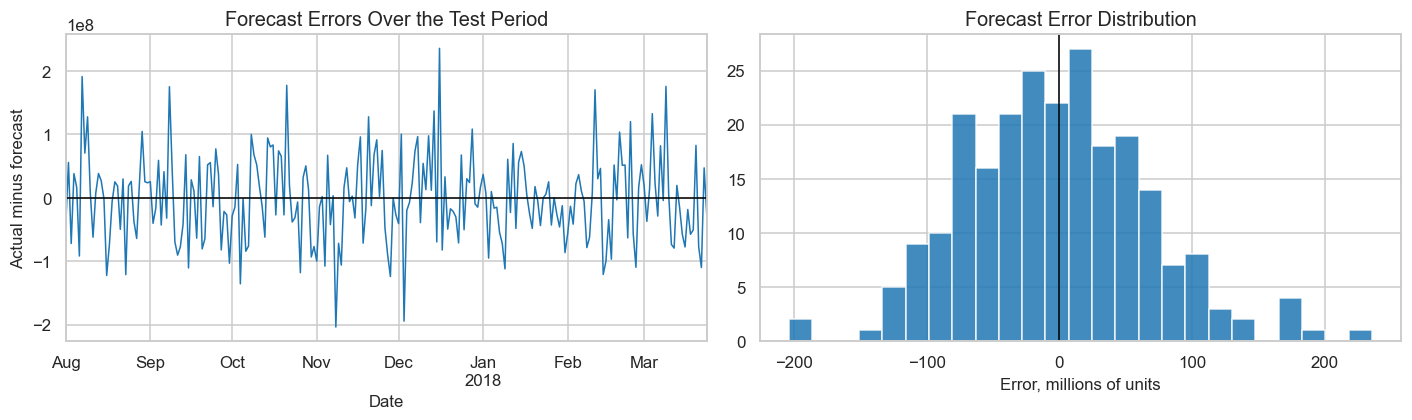

In [25]:
# Residual diagnostics for the selected model.
residuals = comparison['Actual_Total_Volume'] - comparison['Forecast_Total_Volume']
residual_summary = pd.Series({
    'Mean error (millions)': residuals.mean() / 1_000_000,
    'Median error (millions)': residuals.median() / 1_000_000,
    'Error standard deviation (millions)': residuals.std() / 1_000_000,
    '5th percentile (millions)': residuals.quantile(0.05) / 1_000_000,
    '95th percentile (millions)': residuals.quantile(0.95) / 1_000_000,
}, name='value')
display(residual_summary.to_frame().round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
residuals.plot(ax=axes[0], color='tab:blue', linewidth=1)
axes[0].axhline(0, color='black', linewidth=1)
axes[0].set_title('Forecast Errors Over the Test Period')
axes[0].set_ylabel('Actual minus forecast')

axes[1].hist(residuals / 1_000_000, bins=25, color='tab:blue', alpha=0.85)
axes[1].axvline(0, color='black', linewidth=1)
axes[1].set_title('Forecast Error Distribution')
axes[1].set_xlabel('Error, millions of units')
plt.tight_layout()
plt.show()

**Why residual diagnostics were performed:** Aggregate metrics can hide systematic over-forecasting, under-forecasting, or periods with unusually large misses.

**Insight and decision:** Mean residual error is **-2.25 million units** (`actual - forecast`), so the selected LSTM has only a small average over-forecasting bias relative to daily volume. The error standard deviation is **69.17 million**, and the middle 90% of observed errors runs roughly from **-108.25 million to +105.41 million**. This uncertainty is large enough that prediction ranges and regular retraining would be necessary before inventory commitments.

## Insightful Discussion and Final Takeaways

1. **Research question answer:** Historical demand supports a useful forecast of daily mango sales. The selected 30-lag LSTM achieves RMSE of **69.058 million units**, MAE of **54.432 million**, and MAPE of **11.71%** on 236 unseen dates.

2. **Measured value:** The LSTM reduces RMSE by **24.19%** relative to a last-value forecast. Its advantage over the 30-day moving average is only **0.16%**, so the project does not claim that deep learning is automatically superior.

3. **Role of bag sales:** Bag sales are included in EDA and as lagged inputs to the multivariate MLP, multi-headed MLP, CNN, RNN, and LSTM. The lag structure prevents same-day target leakage. The lagged multivariate models did not clearly outperform demand history alone, suggesting that these related sales components add limited incremental signal in their current form.

4. **Business interpretation:** Demand forecasting is more actionable than price forecasting for this dataset because it can support purchasing, stock allocation, packaging capacity, and sales planning.

5. **Limitations:** The dataset does not identify region, store, promotions, weather, holidays, or supply constraints. Evaluation uses one chronological holdout rather than repeated rolling-origin backtests. The course-provided dataset also has no external source URL or documented license.

6. **Recommended next step:** Add external demand drivers, quantify prediction intervals, and repeat the comparison with rolling-origin cross-validation. In a production pilot, run the LSTM beside the moving-average and ARIMA challengers and retrain only when monitored error or data drift justifies it.